# Notebook 01: Data Intake and Quality Audit

**Project:** Global Layoffs Intelligence (Python + PostgreSQL + Power BI + ML)
**Phase:** 1 of 6

This notebook is the first look at the raw data. It **does not clean or change anything**. Its job is to answer one question:

> *Can we trust these two files, and what problems will we need to fix in Phase 2?*

| What this notebook does | What it does **not** do |
|---|---|
| Counts records per source file | Edit or overwrite anything in `data/raw/` |
| Inspects column names and data types | Fill missing values with zero or anything else |
| Measures missing values | Delete rows, even suspicious ones |
| Validates dates and numbers | Merge the two datasets |
| Finds possible duplicates, inside and across files | Decide which duplicate is "right" (that is a human review step) |
| Writes an audit trail of every check | |

**Outputs** (all relative to the project root):

- `data/interim/global_layoffs_staged.csv` and `data/interim/tech_layoffs_staged.csv`: raw values unchanged, plus ID and quality-flag columns
- `data/interim/possible_duplicate_pairs.csv`: cross-source pairs for you to review
- `reports/audit/`: raw-file fingerprints, missing-value tables, audit log, quality summary
- `reports/figures/`: charts

## How to run this notebook

1. Open a terminal in the **project root** (the folder that contains `data/`, `notebooks/` and `requirements.txt`).
2. Create and activate a virtual environment, then install the packages:
   ```bash
   python -m venv .venv
   # Windows:      .venv\Scripts\activate
   # macOS/Linux:  source .venv/bin/activate
   pip install -r requirements.txt
   ```
3. Register the environment as a Jupyter kernel so the notebook can find it:
   ```bash
   python -m ipykernel install --user --name layoffs-env --display-name "Python (layoffs-env)"
   ```
4. Open this notebook in Jupyter or VS Code and **select the kernel "Python (layoffs-env)"**
   (Jupyter: *Kernel → Change kernel*. VS Code: the kernel picker in the top-right corner).
5. Run all cells from the top (*Run → Run All Cells*). The notebook works whether Jupyter starts in the project root or in `notebooks/`.

## 1. Setup: libraries and project paths

**Objective.** Load the three libraries we need and work out where the project folders are on your computer.

**Concept: relative paths.** If we wrote a full path like `C:/Users/akshaya/Desktop/...`, the notebook would break on anyone else's computer.
Instead we find the *project root* (the folder that contains `data/raw/`) and build every other path from it.
`pathlib.Path` lets us join folders with `/`, which works on Windows, macOS and Linux.

In [1]:
from pathlib import Path
import hashlib                      # used to fingerprint the raw files (Section 2)
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


In [2]:
def find_project_root(start: Path) -> Path:
    # Walk up from the current folder until we find one that contains data/raw
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Could not find the project root (a folder containing data/raw). "
                            "Start Jupyter inside the project folder.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR      = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR  = PROJECT_ROOT / "data" / "interim"
AUDIT_DIR    = PROJECT_ROOT / "reports" / "audit"
FIG_DIR      = PROJECT_ROOT / "reports" / "figures"

for folder in [INTERIM_DIR, AUDIT_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)   # create output folders if missing

GLOBAL_FILE = RAW_DIR / "layoffs_2019_2026_sample.csv"   # from archive 5.zip (Fliar Research)
TECH_FILE   = RAW_DIR / "tech_layoffs_2025_2026.csv"

print("Project root:", PROJECT_ROOT)

Project root: /home/claude/global-layoffs-intelligence


**Validation rules live in `src/phase1_validation.py`.** The date and number rules are small functions in a separate file, so the *same* code
is run here on the real data and by `tests/test_phase1_validation.py` on synthetic test rows. We add `src/` to Python's search path so the
notebook can import it. Every function only returns True/False flags; none of them changes a value.

In [3]:
import sys
sys.path.insert(0, str(PROJECT_ROOT / "src"))   # lets Python find src/phase1_validation.py

from phase1_validation import (validation_flags, flag_unparseable_date, flag_date_outside_range,
                               flag_date_after, flag_non_numeric, flag_not_positive, flag_pct_out_of_range,
                               flag_headcount_status_conflict, parse_dates)
print("validation rules loaded from", PROJECT_ROOT / "src" / "phase1_validation.py")

validation rules loaded from /home/claude/global-layoffs-intelligence/src/phase1_validation.py


**Audit trail helper.** Every check in this notebook records one row in an *audit log*: what was checked, how many records, how many issues, and what we did about it.
This log is saved at the end, so anyone can see exactly what happened to the data and why.

In [4]:
audit_log = []   # one dictionary per check; turned into a table in Section 10


def log_check(check, dataset, records_checked, issues_found, action, notes=""):
    audit_log.append({
        "checked_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "check": check,
        "dataset": dataset,
        "records_checked": int(records_checked),
        "issues_found": int(issues_found),
        "action_taken": action,
        "notes": notes,
    })
    print(f"[logged] {check} | {dataset}: {issues_found} issue(s) in {records_checked} record(s)")

## 2. Raw file inventory and fingerprints

**Objective.** List the raw files and record a unique "fingerprint" for each one, so we can prove at the end that we did not change them.

**Concept: file hashes.** A SHA-256 hash turns a file's contents into a 64-character code. Change even one character in the file and the code changes completely.
We compute it now and again in Section 11. If the two codes match, the raw data is untouched, which is a basic rule of reproducible analysis.

In [5]:
def sha256_of(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


raw_manifest = pd.DataFrame([
    {"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1), "sha256": sha256_of(p)}
    for p in sorted(RAW_DIR.iterdir()) if p.is_file()
])
raw_manifest.to_csv(AUDIT_DIR / "raw_file_manifest.csv", index=False)
raw_manifest

,file,size_kb,sha256
0,SOURCE_DATA_CARD.md,102.0,8e93c93c8bd395ac7d4157a17aaaaac4c8aa09a835fd91...
1,layoffs_2019_2026_sample.csv,2126.7,a181c6ce9756b06f70429d3d284262d1662fed3df1a5df...
2,tech_layoffs_2025_2026.csv,4.8,f011a4d0beb884ca3a2526f35ef8fe59799f65b839d086...


## 3. Load the data and count records per source

**Objective.** Read both CSV files into tables (DataFrames) and count how many records each source contributes.

**Concept: source-level counts.** Before any analysis we need a baseline: *how many rows came in from each file?*
Every later step should be able to explain where each of those rows went. We also add three tracking columns:

- `source_file`: which file the row came from
- `source_row_number`: the line in that file (header = line 1, so the first data row is line 2), useful when you open the CSV to check something
- `record_id`: a short ID that is unique across both sources (`G-00001` for the global file, `T-00001` for the tech file)

We read the files with `keep_default_na=False` and then convert only **truly empty cells** to missing.
That stops pandas from quietly treating text such as `"NA"` or `"None"` as missing.

In [6]:
def load_raw(path: Path, prefix: str) -> pd.DataFrame:
    df = pd.read_csv(path, keep_default_na=False, na_values=[""])
    df.insert(0, "record_id", [f"{prefix}-{i:05d}" for i in range(1, len(df) + 1)])
    df.insert(1, "source_file", path.name)
    df.insert(2, "source_row_number", np.arange(2, len(df) + 2))   # line number in the CSV
    return df


global_df = load_raw(GLOBAL_FILE, "G")
tech_df   = load_raw(TECH_FILE, "T")

source_counts = pd.DataFrame({
    "source_file": [GLOBAL_FILE.name, TECH_FILE.name],
    "records": [len(global_df), len(tech_df)],
    "columns_in_file": [global_df.shape[1] - 3, tech_df.shape[1] - 3],   # minus our 3 tracking columns
})
source_counts

,source_file,records,columns_in_file
0,layoffs_2019_2026_sample.csv,5000,20
1,tech_layoffs_2025_2026.csv,35,16


In [7]:
# Validation: the number of rows loaded must equal the number of data lines in each file
for path, df in [(GLOBAL_FILE, global_df), (TECH_FILE, tech_df)]:
    data_lines = len(pd.read_csv(path, usecols=[0]))     # independent re-count
    assert len(df) == data_lines, f"Row count mismatch for {path.name}"
    assert df["record_id"].is_unique
    log_check("source record count", path.name, len(df), 0, "none (baseline recorded)")

[logged] source record count | layoffs_2019_2026_sample.csv: 0 issue(s) in 5000 record(s)
[logged] source record count | tech_layoffs_2025_2026.csv: 0 issue(s) in 35 record(s)


**What we found.** 5,000 records from the global file (20 columns) and 35 from the tech file (16 columns). Both re-counts match, so nothing was lost while loading.
The global file is a 26% sample of 19,208 events, so its totals are **not** the full market totals in the data card.

## 4. Schema inspection

**Objective.** See which columns each file has, what type of data is in them, and how the two files' columns relate to each other.

**Concept: schema.** The *schema* is the list of columns and their data types. Two files about the same topic rarely use the same schema
(for example `Company` vs `company_name`, or `USA` vs `United States`). Mapping them side by side now tells us what Phase 2 must standardise
before the data can go into one PostgreSQL table.

In [8]:
def schema_table(df: pd.DataFrame) -> pd.DataFrame:
    cols = [c for c in df.columns if c not in ("record_id", "source_file", "source_row_number")]
    return pd.DataFrame({
        "column": cols,
        "pandas_dtype": [str(df[c].dtype) for c in cols],
        "non_missing": [df[c].notna().sum() for c in cols],
        "unique_values": [df[c].nunique() for c in cols],
        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in cols],
    })


print("GLOBAL dataset schema")
schema_table(global_df)

GLOBAL dataset schema


,column,pandas_dtype,non_missing,unique_values,example
0,layoff_id,str,5000,5000,3eabf5c11805
1,date,str,5000,1867,2019-01-04
2,year,int64,5000,8,2019
3,month,str,5000,90,2019-01
4,company_name,str,5000,3497,Popular's integration into Santander
5,company_domain,str,3735,2374,selectabio.com
6,country,str,4530,112,United States
7,company_country,str,3355,83,United States
8,company_state,str,2067,57,New York
9,company_city,str,3440,917,Watertown


In [9]:
print("TECH dataset schema")
schema_table(tech_df)

TECH dataset schema


,column,pandas_dtype,non_missing,unique_values,example
0,Company,str,35,35,Duolingo
1,Employees_Laid_Off,int64,35,32,250
2,Date,str,35,33,2025-01-08
3,Industry,str,35,27,EdTech
4,Location,str,35,21,"Pittsburgh, PA"
5,Country,str,35,5,USA
6,Reason,str,35,31,AI replacing content creators
7,Department,str,35,25,"Content, Marketing"
8,Percentage_Workforce,float64,35,26,10.0
9,Total_Employees,int64,35,34,2500


**Column mapping between the two sources.** This is written by hand from the two tables above. Columns that exist in only one source are listed too,
because they decide what each dataset can be used for.

In [10]:
column_map = pd.DataFrame([
    ("company",            "company_name",                "Company",              "Name styles differ, e.g. 'X (Twitter)' vs 'Twitter'"),
    ("layoff date",        "date",                        "Date",                 "Both ISO yyyy-mm-dd text"),
    ("people laid off",    "headcount_cut",               "Employees_Laid_Off",   "Global: only filled when verified"),
    ("% of workforce",     "pct_workforce",               "Percentage_Workforce", ""),
    ("country",            "country / company_country",   "Country",              "Global has 2 country columns; tech uses 'USA'"),
    ("city / location",    "company_city, company_state", "Location",             "Tech combines city and state in one text"),
    ("industry",           "sector",                      "Industry",             "Different category lists"),
    ("year / month",       "year, month",                 "Year, Month, Month_Name, Quarter", "Derived from the date in both"),
    ("reason",             "(news_excerpt text only)",    "Reason",               "Global has no reason column"),
    ("AI-related flag",    "-",                           "AI_Related",           "Tech only"),
    ("company size",       "-",                           "Total_Employees",      "Tech only"),
    ("severance",          "-",                           "Severance_Weeks",      "Tech only"),
    ("department",         "-",                           "Department",           "Tech only"),
    ("furlough flag",      "is_furlough",                 "-",                    "Global only"),
    ("headcount quality",  "headcount_status",            "-",                    "Global only"),
    ("news source",        "news_source, news_url, news_excerpt, news_mentions", "-", "Global only"),
], columns=["concept", "global_column", "tech_column", "note"])
column_map.to_csv(AUDIT_DIR / "column_mapping.csv", index=False)
column_map

,concept,global_column,tech_column,note
0,company,company_name,Company,"Name styles differ, e.g. 'X (Twitter)' vs 'Twi..."
1,layoff date,date,Date,Both ISO yyyy-mm-dd text
2,people laid off,headcount_cut,Employees_Laid_Off,Global: only filled when verified
3,% of workforce,pct_workforce,Percentage_Workforce,
4,country,country / company_country,Country,Global has 2 country columns; tech uses 'USA'
5,city / location,"company_city, company_state",Location,Tech combines city and state in one text
6,industry,sector,Industry,Different category lists
7,year / month,"year, month","Year, Month, Month_Name, Quarter",Derived from the date in both
8,reason,(news_excerpt text only),Reason,Global has no reason column
9,AI-related flag,-,AI_Related,Tech only


## 5. Missing-value analysis

**Objective.** Measure how much of each column is empty, in both files.

**Concept: why missing values matter.** A missing headcount is *not* zero people laid off. It means *the number was not reported*.
If we filled it with 0, totals and averages would be badly wrong. So in this phase we only **measure** missingness.
We also check for cells that look filled but only contain spaces, which pandas would not count as missing.

In [11]:
def missing_summary(df: pd.DataFrame, name: str) -> pd.DataFrame:
    cols = [c for c in df.columns if c not in ("record_id", "source_file", "source_row_number")]
    # text columns: works the same in pandas 2 and pandas 3
    text_cols = [c for c in cols if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
    blank_only = {c: (df[c].astype("string").str.strip() == "").sum() for c in text_cols}
    # filled cells with spaces or line breaks at the start/end (e.g. "\n  https://...")
    padded = {c: (df[c].notna() & (df[c].astype("string") != df[c].astype("string").str.strip())).sum()
              for c in text_cols}
    out = pd.DataFrame({
        "dataset": name,
        "column": cols,
        "missing": [df[c].isna().sum() for c in cols],
        "whitespace_only": [blank_only.get(c, 0) for c in cols],
        "leading_trailing_space": [padded.get(c, 0) for c in cols],
    })
    out["missing_pct"] = (100 * out["missing"] / len(df)).round(1)
    return out.sort_values("missing_pct", ascending=False)


missing_global = missing_summary(global_df, "global")
missing_tech   = missing_summary(tech_df, "tech")
pd.concat([missing_global, missing_tech]).to_csv(AUDIT_DIR / "missing_values_summary.csv", index=False)
missing_global

,dataset,column,missing,whitespace_only,leading_trailing_space,missing_pct
13,global,pct_workforce,3879,0,0,77.6
8,global,company_state,2933,0,0,58.7
11,global,headcount_cut,2511,0,0,50.2
7,global,company_country,1645,0,0,32.9
16,global,news_source,1611,0,0,32.2
17,global,news_url,1611,0,6,32.2
10,global,sector,1564,0,0,31.3
9,global,company_city,1560,0,0,31.2
19,global,fliar_profile_url,1404,0,0,28.1
5,global,company_domain,1265,0,0,25.3


In [12]:
missing_tech[missing_tech["missing"] > 0]   # empty table = no missing values in the tech file

,dataset,column,missing,whitespace_only,leading_trailing_space,missing_pct


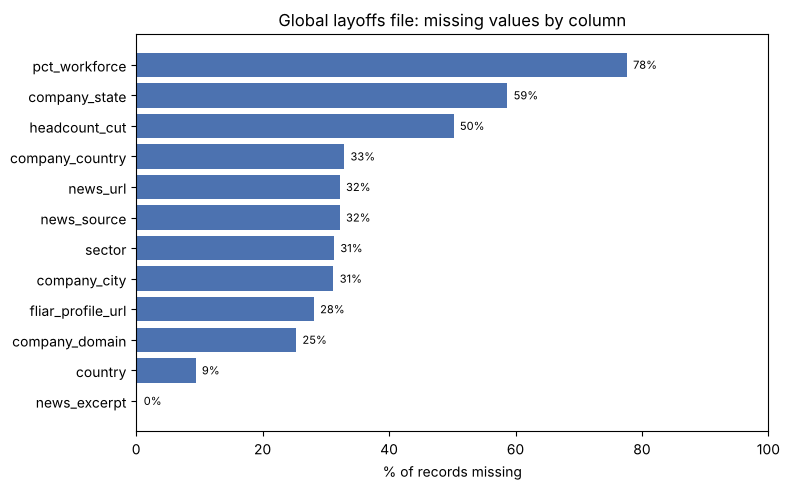

In [13]:
# Chart: share of missing values per column (global file only; the tech file has none)
plot_data = missing_global[missing_global["missing_pct"] > 0].sort_values("missing_pct")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data["column"], plot_data["missing_pct"], color="#4C72B0")
ax.set_xlabel("% of records missing")
ax.set_title("Global layoffs file: missing values by column")
ax.set_xlim(0, 100)
for y, v in enumerate(plot_data["missing_pct"]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "01_missing_values_global.png", dpi=150)
plt.show()

**What we found.**
- The **tech file has no missing values** at all. The global file has gaps in 12 of its 20 columns.
- `pct_workforce` is missing in 78% of global rows and `headcount_cut` in 50%. **Size-based analysis can only use about half of the events**, and must say so.
- `sector` is missing in 31% and `country` in 9%, so "Unknown" will be a real category in charts rather than something to hide.
- 6 `news_url` cells start with a line break and spaces. They look filled but would break joins and URL links; Phase 2 strips them.

**Concept: is the missingness random?** The global file has a `headcount_status` column. If headcount is missing *because* the number was not verified,
that is an explainable pattern, not random gaps. The cross-table below checks this.

In [14]:
headcount_check = pd.crosstab(
    global_df["headcount_status"],
    global_df["headcount_cut"].notna().map({True: "headcount present", False: "headcount missing"}),
    margins=True,
)
headcount_check

headcount_cut,headcount missing,headcount present,All
headcount_status,,,
failed_check,1314,0,1314
not_disclosed,1197,0,1197
verified,0,2489,2489
All,2511,2489,5000


In [15]:
# Validation: any 'verified' row without a number, or a non-verified row WITH a number, is inconsistent
inconsistent = global_df[flag_headcount_status_conflict(global_df["headcount_cut"], global_df["headcount_status"])]
log_check("missing values (all columns)", "global", len(global_df), (missing_global["missing"] > 0).sum(),
          "measured only; nothing filled", "count = columns with at least one missing value")
log_check("missing values (all columns)", "tech", len(tech_df), (missing_tech["missing"] > 0).sum(),
          "measured only; nothing filled")
padded_cols = missing_global[missing_global["leading_trailing_space"] > 0]
log_check("text with leading/trailing spaces", "global", len(global_df), padded_cols["leading_trailing_space"].sum(),
          "flagged only; strip in Phase 2", ", ".join(padded_cols["column"]))
log_check("headcount vs headcount_status consistency", "global", len(global_df), len(inconsistent),
          "flagged only")
print("Inconsistent rows:", len(inconsistent))

[logged] missing values (all columns) | global: 12 issue(s) in 5000 record(s)
[logged] missing values (all columns) | tech: 0 issue(s) in 35 record(s)
[logged] text with leading/trailing spaces | global: 6 issue(s) in 5000 record(s)
[logged] headcount vs headcount_status consistency | global: 0 issue(s) in 5000 record(s)
Inconsistent rows: 0


**What we found.** Headcount is missing for **exactly** the rows whose status is `failed_check` or `not_disclosed`, and present for every `verified` row.
So the gaps are explained by the source's own verification process, not by random errors. This tells us: *only verified headcounts are usable*, and the
ML target in Phase 5 must be built only from events whose size is known.

## 6. Date validation

**Objective.** Check that every date can be read as a real calendar date, sits inside the expected period, and agrees with the year/month columns that were derived from it.

**Concept: why dates need checking.** Dates drive every trend chart and every time-based feature in the ML model.
Common problems are text that is not a date, impossible dates (like 2025-02-30), dates in the future, and helper columns (Year, Month) that disagree with the date itself.
`pd.to_datetime(..., errors="coerce")` turns anything it cannot read into `NaT` ("not a time") instead of crashing, so we can count the failures.
The parsed dates go into **new** columns (`date_parsed`), so the original text stays unchanged.

In [16]:
global_df["date_parsed"] = parse_dates(global_df["date"])   # yyyy-mm-dd; unreadable -> NaT
tech_df["date_parsed"]   = parse_dates(tech_df["Date"])

# The data card says the global data runs Jan 2019 - Jun 2026; the tech file is labelled 2025-2026
EXPECTED_RANGE = {"global": ("2019-01-01", "2026-06-30"), "tech": ("2025-01-01", "2026-12-31")}
AUDIT_DATE = pd.Timestamp("2026-10-23")   # date this audit was run; later dates would be "in the future"

date_report = []
for name, df, col in [("global", global_df, "date"), ("tech", tech_df, "Date")]:
    start, end = EXPECTED_RANGE[name]
    date_report.append({
        "dataset": name,
        "records": len(df),
        "unparseable": flag_unparseable_date(df[col]).sum(),
        "earliest": df["date_parsed"].min().date(),
        "latest": df["date_parsed"].max().date(),
        "outside_expected_range": flag_date_outside_range(df[col], start, end).sum(),
        "after_audit_date": flag_date_after(df[col], AUDIT_DATE).sum(),
    })
date_report = pd.DataFrame(date_report)
date_report

,dataset,records,unparseable,earliest,latest,outside_expected_range,after_audit_date
0,global,5000,0,2019-01-04,2026-06-14,0,0
1,tech,35,0,2025-01-08,2026-02-12,0,0


In [17]:
# Do the derived columns agree with the date?
global_year_mismatch  = (global_df["year"] != global_df["date_parsed"].dt.year).sum()
global_month_mismatch = (global_df["month"] != global_df["date_parsed"].dt.strftime("%Y-%m")).sum()

tech_year_mismatch    = (tech_df["Year"] != tech_df["date_parsed"].dt.year).sum()
tech_month_mismatch   = (tech_df["Month"] != tech_df["date_parsed"].dt.month).sum()
tech_quarter_mismatch = (tech_df["Quarter"] != tech_df["date_parsed"].dt.quarter).sum()
tech_name_mismatch    = (tech_df["Month_Name"] != tech_df["date_parsed"].dt.month_name()).sum()

print("global: year mismatches", global_year_mismatch, "| month mismatches", global_month_mismatch)
print("tech:   year", tech_year_mismatch, "| month", tech_month_mismatch,
      "| quarter", tech_quarter_mismatch, "| month name", tech_name_mismatch)

global: year mismatches 0 | month mismatches 0
tech:   year 0 | month 0 | quarter 0 | month name 0


In [18]:
for name, row in date_report.set_index("dataset").iterrows():
    log_check("date parse", name, row["records"], row["unparseable"], "flagged only (original text kept)")
    log_check("date within expected range", name, row["records"], row["outside_expected_range"], "flagged only",
              f"expected {EXPECTED_RANGE[name][0]} to {EXPECTED_RANGE[name][1]}")
    log_check("date after audit date (future)", name, row["records"], row["after_audit_date"], "flagged only",
              f"audit date {AUDIT_DATE.date()}")
log_check("derived year/month agree with date", "global", len(global_df),
          global_year_mismatch + global_month_mismatch, "none needed if 0")
log_check("derived year/month/quarter/name agree with date", "tech", len(tech_df),
          tech_year_mismatch + tech_month_mismatch + tech_quarter_mismatch + tech_name_mismatch, "none needed if 0")

[logged] date parse | global: 0 issue(s) in 5000 record(s)
[logged] date within expected range | global: 0 issue(s) in 5000 record(s)
[logged] date after audit date (future) | global: 0 issue(s) in 5000 record(s)
[logged] date parse | tech: 0 issue(s) in 35 record(s)
[logged] date within expected range | tech: 0 issue(s) in 35 record(s)
[logged] date after audit date (future) | tech: 0 issue(s) in 35 record(s)
[logged] derived year/month agree with date | global: 0 issue(s) in 5000 record(s)
[logged] derived year/month/quarter/name agree with date | tech: 0 issue(s) in 35 record(s)


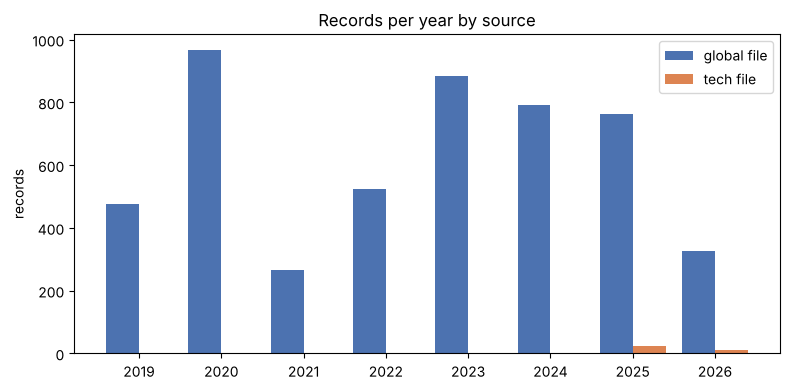

date_parsed,2019,2020,2021,2022,2023,2024,2025,2026
global,476,968,265,525,885,791,762,328
tech,0,0,0,0,0,0,25,10


In [19]:
# Chart: records per year from each source, to see how the two files overlap in time
per_year = pd.DataFrame({
    "global": global_df["date_parsed"].dt.year.value_counts(),
    "tech": tech_df["date_parsed"].dt.year.value_counts(),
}).fillna(0).astype(int).sort_index()     # fillna(0) here is a COUNT of rows, so 0 is correct

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(per_year))
ax.bar(x - 0.2, per_year["global"], width=0.4, label="global file", color="#4C72B0")
ax.bar(x + 0.2, per_year["tech"], width=0.4, label="tech file", color="#DD8452")
ax.set_xticks(x, per_year.index)
ax.set_ylabel("records")
ax.set_title("Records per year by source")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "01_records_per_year_by_source.png", dpi=150)
plt.show()
per_year.T

**What we found.** All 5,035 dates are valid calendar dates and fall inside the expected periods (global: 4 Jan 2019 to 14 Jun 2026;
tech: 8 Jan 2025 to 12 Feb 2026). None are in the future, and every Year, Month, Quarter and Month_Name value agrees with its date.
The two files overlap only in 2025-2026, which is exactly where cross-source duplicates can occur (Section 9).

## 7. Value checks on numbers and categories

**Objective.** Look for numbers that cannot be right (negative headcounts, percentages above 100) and for category labels that are spelled differently but mean the same thing.

**Concept: plausibility checks.** A layoff of -50 people or 140% of the workforce is impossible, so it must be a data-entry or extraction error.
The tech file also lets us cross-check three numbers against each other:
`Employees_Laid_Off` should be roughly `Percentage_Workforce × Total_Employees / 100`. A large gap means one of the three is wrong.

In [20]:
range_checks = pd.DataFrame([
    ("global", "headcount_cut <= 0",           flag_not_positive(global_df["headcount_cut"]).sum()),
    ("global", "pct_workforce <= 0 or > 100",  flag_pct_out_of_range(global_df["pct_workforce"]).sum()),
    ("global", "news_mentions < 1",            (global_df["news_mentions"] < 1).sum()),
    ("tech",   "Employees_Laid_Off <= 0",      flag_not_positive(tech_df["Employees_Laid_Off"]).sum()),
    ("tech",   "Percentage_Workforce <= 0 or > 100", flag_pct_out_of_range(tech_df["Percentage_Workforce"]).sum()),
    ("tech",   "Laid off > Total_Employees",   (tech_df["Employees_Laid_Off"] > tech_df["Total_Employees"]).sum()),
    ("tech",   "Severance_Weeks < 0",          (tech_df["Severance_Weeks"] < 0).sum()),
], columns=["dataset", "rule", "violations"])

for _, r in range_checks.iterrows():
    log_check(f"range rule: {r['rule']}", r["dataset"], len(global_df if r["dataset"] == "global" else tech_df),
              r["violations"], "flagged only")
range_checks

[logged] range rule: headcount_cut <= 0 | global: 0 issue(s) in 5000 record(s)
[logged] range rule: pct_workforce <= 0 or > 100 | global: 0 issue(s) in 5000 record(s)
[logged] range rule: news_mentions < 1 | global: 0 issue(s) in 5000 record(s)
[logged] range rule: Employees_Laid_Off <= 0 | tech: 0 issue(s) in 35 record(s)
[logged] range rule: Percentage_Workforce <= 0 or > 100 | tech: 0 issue(s) in 35 record(s)
[logged] range rule: Laid off > Total_Employees | tech: 0 issue(s) in 35 record(s)
[logged] range rule: Severance_Weeks < 0 | tech: 0 issue(s) in 35 record(s)


,dataset,rule,violations
0,global,headcount_cut <= 0,0
1,global,pct_workforce <= 0 or > 100,0
2,global,news_mentions < 1,0
3,tech,Employees_Laid_Off <= 0,0
4,tech,Percentage_Workforce <= 0 or > 100,0
5,tech,Laid off > Total_Employees,0
6,tech,Severance_Weeks < 0,0


**Concept: text in a number column.** If one cell in a number column contains text (for example `"twelve hundred"` or `"15%"`),
pandas reads the *whole column* as text and the checks above would crash. This rule finds filled cells that cannot be read as a number.
Empty cells are **not** flagged here, because missing is a different issue (Section 5).

In [21]:
NUMERIC_COLUMNS = {
    "global": (global_df, ["headcount_cut", "pct_workforce", "news_mentions"]),
    "tech":   (tech_df, ["Employees_Laid_Off", "Percentage_Workforce", "Total_Employees", "Severance_Weeks"]),
}
non_numeric_report = []
for name, (df, cols) in NUMERIC_COLUMNS.items():
    for col in cols:
        n_bad = flag_non_numeric(df[col]).sum()
        non_numeric_report.append({"dataset": name, "column": col, "non_numeric_cells": n_bad})
        log_check(f"non-numeric value in {col}", name, len(df), n_bad, "flagged only")
pd.DataFrame(non_numeric_report)

[logged] non-numeric value in headcount_cut | global: 0 issue(s) in 5000 record(s)
[logged] non-numeric value in pct_workforce | global: 0 issue(s) in 5000 record(s)
[logged] non-numeric value in news_mentions | global: 0 issue(s) in 5000 record(s)
[logged] non-numeric value in Employees_Laid_Off | tech: 0 issue(s) in 35 record(s)
[logged] non-numeric value in Percentage_Workforce | tech: 0 issue(s) in 35 record(s)
[logged] non-numeric value in Total_Employees | tech: 0 issue(s) in 35 record(s)
[logged] non-numeric value in Severance_Weeks | tech: 0 issue(s) in 35 record(s)


,dataset,column,non_numeric_cells
0,global,headcount_cut,0
1,global,pct_workforce,0
2,global,news_mentions,0
3,tech,Employees_Laid_Off,0
4,tech,Percentage_Workforce,0
5,tech,Total_Employees,0
6,tech,Severance_Weeks,0


In [22]:
# Tech file cross-check: does laid-off count match % x total employees?
implied = tech_df["Percentage_Workforce"] * tech_df["Total_Employees"] / 100
tech_df["implied_vs_reported_gap_pct"] = (100 * (tech_df["Employees_Laid_Off"] - implied) / implied).round(1)

big_gap = tech_df[tech_df["implied_vs_reported_gap_pct"].abs() > 10]
log_check("laid off ~= pct x total employees (within 10%)", "tech", len(tech_df), len(big_gap), "flagged only")
tech_df[["record_id", "Company", "Employees_Laid_Off", "Percentage_Workforce", "Total_Employees",
         "implied_vs_reported_gap_pct"]].sort_values("implied_vs_reported_gap_pct", key=abs, ascending=False).head(10)

[logged] laid off ~= pct x total employees (within 10%) | tech: 0 issue(s) in 35 record(s)


,record_id,Company,Employees_Laid_Off,Percentage_Workforce,Total_Employees,implied_vs_reported_gap_pct
1,T-00002,Twitch,500,35.0,1400,2.0
23,T-00024,Spotify,1500,17.0,9000,-2.0
5,T-00006,PayPal,2500,9.0,28000,-0.8
33,T-00034,Google,2500,1.4,180000,-0.8
14,T-00015,Dropbox,500,16.0,3100,0.8
11,T-00012,IBM,3900,1.4,280000,-0.5
31,T-00032,Meta,5000,7.5,67000,-0.5
10,T-00011,Stripe,1100,14.0,7900,-0.5
8,T-00009,Cisco,7000,8.5,82000,0.4
20,T-00021,Salesforce,4000,5.5,73000,-0.4


**Concept: category consistency.** Labels such as `USA` and `United States` describe the same country but would be counted separately in SQL and Power BI.
Here we only **list** the variants; Phase 2 will map them to one standard value.

In [23]:
print("Tech file countries:   ", sorted(tech_df["Country"].unique()))
print("Global file has", global_df["country"].nunique(), "country labels, e.g.:")
odd_countries = sorted(c for c in global_df["country"].dropna().unique() if "(" in c)
print("  labels with a bracketed suffix:", odd_countries)
print("Tech AI_Related values:", tech_df["AI_Related"].value_counts().to_dict())
print("Global headcount_status values:", global_df["headcount_status"].value_counts().to_dict())

Tech file countries:    ['Canada', 'Germany', 'Ireland', 'Sweden', 'USA']
Global file has 112 country labels, e.g.:
  labels with a bracketed suffix: ['United Kingdom (uk)', 'United States (cnmi)', 'United States (usa)']
Tech AI_Related values: {'No': 20, 'Yes': 9, 'Partial': 6}
Global headcount_status values: {'verified': 2489, 'failed_check': 1314, 'not_disclosed': 1197}


In [24]:
# Company names in the global file that look like sentence fragments or carry legal suffixes
name_issue_pattern = r"\b(?:Inc|Corp|Ltd|LLC|plc|Limited|Corporation)\b\.?|\s{2,}|^\W"
noisy_names = global_df[global_df["company_name"].str.contains(name_issue_pattern, regex=True)]
long_names  = global_df[global_df["company_name"].str.split().str.len() >= 5]

log_check("company name has legal suffix / odd spacing", "global", len(global_df), len(noisy_names), "flagged only")
log_check("company name looks like a sentence (5+ words)", "global", len(global_df), len(long_names), "flagged only")
long_names[["record_id", "company_name", "date"]].head(10)

[logged] company name has legal suffix / odd spacing | global: 127 issue(s) in 5000 record(s)
[logged] company name looks like a sentence (5+ words) | global: 84 issue(s) in 5000 record(s)


,record_id,company_name,date
20,G-00021,Electric-car maker Tesla Inc. TSLA,2019-01-18
41,G-00042,Cooper Tire & Rubber Company Europe,2019-02-07
103,G-00104,Goodyear Tire & Rubber Co,2019-03-21
188,G-00189,MAG – Maschinen und Apparatebau Aktiengesellsc...,2019-06-04
278,G-00279,Federation of Automobile Dealers Association,2019-08-04
282,G-00283,Honda Motocycle & Scooter India,2019-08-06
288,G-00289,F Smales & Son (Fish Merchants) Ltd,2019-08-07
301,G-00302,São Paulo Banco do Brasil,2019-08-20
431,G-00432,U.S. Silica Holdings Inc. SLCA,2019-11-22
454,G-00455,Meridian Magnesium Products of America,2019-12-14


**What we found.**
- No impossible numbers: no negative headcounts, no percentages outside 0-100, no layoff bigger than the company.
- In the tech file, laid-off count, percentage and total employees agree within 2% for every row. That is *suspiciously* tidy for real news data,
  where these three numbers usually come from different reports. Keep this in mind together with the Section 9 findings.
- Naming is inconsistent: `USA` (tech) vs `United States` (global), and global labels like `United States (usa)` and `United Kingdom (uk)`.
- 198 global company names are noisy: legal suffixes (`Goodyear Tire & Rubber Co`) or sentence fragments (`Electric-car maker Tesla Inc. TSLA`).
  These stop the same company from grouping together and are listed for Phase 2.

## 8. Duplicate detection inside each file

**Objective.** Find rows that may describe the same layoff twice *within the same file*.

**Concept: exact vs possible duplicates.** An *exact* duplicate is the same row copied twice. A *possible* duplicate is two rows that look like the same event
reported differently, for example the same company on dates a few weeks apart. Exact duplicates are easy; possible duplicates need human judgement,
so we **flag** them and never delete automatically.

The global file's data card says reports of one layoff round were already merged when they were *within 45 days* for the same company.
Counting same-company rows less than 45 days apart is therefore a test of that claim.

In [25]:
original_global_cols = [c for c in global_df.columns
                        if c not in ("record_id", "source_file", "source_row_number", "date_parsed")]
original_tech_cols   = [c for c in tech_df.columns
                        if c not in ("record_id", "source_file", "source_row_number", "date_parsed",
                                     "implied_vs_reported_gap_pct")]

dup_checks = {
    ("global", "exact duplicate rows"):           global_df.duplicated(subset=original_global_cols, keep=False),
    ("global", "duplicate layoff_id"):            global_df["layoff_id"].duplicated(keep=False),
    ("global", "same company + same date"):       global_df.duplicated(subset=["company_name", "date"], keep=False),
    ("global", "same news_url used by 2+ rows"):  global_df["news_url"].notna() & global_df["news_url"].duplicated(keep=False),
    ("tech",   "exact duplicate rows"):           tech_df.duplicated(subset=original_tech_cols, keep=False),
    ("tech",   "same company appears 2+ times"):  tech_df["Company"].duplicated(keep=False),
}
dup_summary = pd.DataFrame(
    [(ds, rule, int(mask.sum())) for (ds, rule), mask in dup_checks.items()],
    columns=["dataset", "rule", "rows_flagged"],
)
dup_summary

,dataset,rule,rows_flagged
0,global,exact duplicate rows,0
1,global,duplicate layoff_id,0
2,global,same company + same date,0
3,global,same news_url used by 2+ rows,350
4,tech,exact duplicate rows,0
5,tech,same company appears 2+ times,0


In [26]:
# Same company, two rows less than 45 days apart (tests the data card's merge rule)
g = global_df.sort_values(["company_name", "date_parsed"])
gap_days = g.groupby("company_name")["date_parsed"].diff().dt.days     # days since the company's previous row
close_rounds = g[gap_days < 45]
print("Same-company rows less than 45 days after the previous row:", len(close_rounds))

for (ds, rule), mask in dup_checks.items():
    log_check(f"duplicates: {rule}", ds, len(global_df if ds == "global" else tech_df), mask.sum(), "flagged only")
log_check("duplicates: same company within 45 days", "global", len(global_df), len(close_rounds), "flagged only",
          "data card says these were merged upstream")

Same-company rows less than 45 days after the previous row: 0
[logged] duplicates: exact duplicate rows | global: 0 issue(s) in 5000 record(s)
[logged] duplicates: duplicate layoff_id | global: 0 issue(s) in 5000 record(s)
[logged] duplicates: same company + same date | global: 0 issue(s) in 5000 record(s)
[logged] duplicates: same news_url used by 2+ rows | global: 350 issue(s) in 5000 record(s)
[logged] duplicates: exact duplicate rows | tech: 0 issue(s) in 35 record(s)
[logged] duplicates: same company appears 2+ times | tech: 0 issue(s) in 35 record(s)
[logged] duplicates: same company within 45 days | global: 0 issue(s) in 5000 record(s)


**Shared news URLs.** One article can mention several layoffs, so a shared URL is not proof of a duplicate. The table below shows
whether the rows sharing a URL are different companies (fine) or the same company (worth reviewing).

In [27]:
shared_url = global_df[dup_checks[("global", "same news_url used by 2+ rows")]]
url_groups = shared_url.groupby("news_url").agg(rows=("record_id", "count"),
                                                 companies=("company_name", "nunique"))
url_same_company = url_groups[url_groups["companies"] < url_groups["rows"]]

print("URLs shared by 2+ rows:", len(url_groups))
print("...of which some rows are the SAME company:", len(url_same_company))
shared_url[shared_url["news_url"].isin(url_same_company.index)][
    ["record_id", "company_name", "date", "headcount_cut", "news_url"]].sort_values("news_url").head(10)

URLs shared by 2+ rows: 147
...of which some rows are the SAME company: 19


,record_id,company_name,date,headcount_cut,news_url
3167,G-03168,SonderMind,2024-01-16,49.0,\n https://endpts.com/mental-health-tech-un...
2218,G-02219,SonderMind,2022-12-16,50.0,\n https://endpts.com/mental-health-tech-un...
2915,G-02916,DealShare,2023-09-20,130.0,https://economictimes.indiatimes.com/tech/star...
2822,G-02823,DealShare,2023-08-05,NaN,https://economictimes.indiatimes.com/tech/star...
1503,G-01504,Canopy Growth,2021-02-09,NaN,https://mugglehead.com/canopy-shares-surge-on-...
1431,G-01432,Canopy Growth,2020-12-09,NaN,https://mugglehead.com/canopy-shares-surge-on-...
3175,G-03176,Unico,2024-01-18,NaN,https://startups.com.br/negocios/demissoes/12-...
2290,G-02291,Unico,2023-01-19,110.0,https://startups.com.br/negocios/demissoes/12-...
4,G-00005,Bosch,2019-01-07,NaN,https://time.news/bosch-will-eliminate-5500-jo...
1524,G-01525,Bosch,2021-02-25,336.0,https://time.news/bosch-will-eliminate-5500-jo...


In [28]:
same_company_url_ids = set(shared_url.loc[shared_url["news_url"].isin(url_same_company.index), "record_id"])
log_check("duplicates: same company + same news_url", "global", len(global_df), len(same_company_url_ids),
          "flagged only")

[logged] duplicates: same company + same news_url | global: 42 issue(s) in 5000 record(s)


**What we found.**
- **No exact duplicates** and no repeated IDs in either file.
- **No same-company rows within 45 days**, which confirms the data card's claim that repeat reports were merged upstream.
- 350 rows share a news URL with another row, but most are one article covering several companies. Only **42 rows (19 URLs)** are the same company
  citing the same article on different dates, for example SonderMind in Dec 2022 and Jan 2024. These are possible duplicates, flagged for review, not deleted.

## 9. Cross-source duplicate candidates

**Objective.** Find pairs where a row in the tech file and a row in the global file might be **the same layoff event**, and save them for you to review.

**Concept: why we cannot just stack the two files.** Both files cover 2025-2026 and include big tech companies. If Intel's August 2025 layoff appears in both,
simply appending the files would count it twice and inflate every total. We also cannot assume a company name match means the same event,
because many companies have several layoff rounds.

**How we match (step by step):**

1. **Normalise company names** so `"Tesla Inc."` and `"tesla"` compare equal: lower-case, remove punctuation and legal suffixes (Inc, Corp, Ltd...).
   A bracketed part becomes an extra alias, so `"X (Twitter)"` can match `"Twitter"`.
2. **Pair** every tech row with every global row whose normalised name is equal, or contains the tech name as a whole word (for names like *"Electric-car maker Tesla Inc"*).
3. **Score** each pair using the date gap and the headcount difference.
4. **Keep** pairs that are close in time (within 120 days) *or* have nearly the same headcount (within 5%), since an identical headcount on a different date can mean one source has the date wrong.

| confidence | rule |
|---|---|
| high | exact name, dates within 45 days, headcount within 10% (or one headcount unknown) |
| medium | dates within 120 days, **or** same headcount within 5% on any date |
| low | everything else that passed step 4 (partial name match) |

Every pair starts with `review_status = "pending_review"`. You decide in the CSV; nothing is merged or deleted here.

In [29]:
import re   # regular expressions: pattern matching on text

LEGAL_SUFFIXES = r"\b(inc|incorporated|corp|corporation|co|company|ltd|limited|llc|plc|group|holdings|sa|ag|gmbh)\b"


def normalise_name(name: str) -> str:
    name = name.lower()
    name = re.sub(r"\(.*?\)", " ", name)        # drop bracketed text (kept separately as an alias)
    name = re.sub(r"[^a-z0-9 ]", " ", name)     # punctuation -> space
    name = re.sub(LEGAL_SUFFIXES, " ", name)
    return " ".join(name.split())               # collapse repeated spaces


def name_aliases(name: str) -> set:
    aliases = {normalise_name(name)}
    for inside in re.findall(r"\((.*?)\)", name):  # "X (Twitter)" -> also "twitter"
        aliases.add(normalise_name(inside))
    return {a for a in aliases if a}


# quick self-test of the helper functions
assert normalise_name("Tesla Inc.") == "tesla"
assert name_aliases("X (Twitter)") == {"x", "twitter"}
print("name helpers OK")

name helpers OK


In [30]:
global_df["name_norm"] = global_df["company_name"].map(normalise_name)

candidate_rows = []
for _, t in tech_df.iterrows():
    for alias in name_aliases(t["Company"]):
        exact = global_df["name_norm"] == alias
        # whole-word containment, only for names of 4+ letters so "x" does not match everything
        partial = (global_df["name_norm"].str.contains(rf"\b{re.escape(alias)}\b", regex=True)
                   if len(alias) >= 4 else pd.Series(False, index=global_df.index))
        for gi in global_df.index[exact | partial]:
            candidate_rows.append({
                "tech_record_id": t["record_id"],
                "global_record_id": global_df.at[gi, "record_id"],
                "name_match": "exact" if exact[gi] else "partial",
                "matched_alias": alias,
            })

candidates = pd.DataFrame(candidate_rows).drop_duplicates(["tech_record_id", "global_record_id"])
print("Same-company pairs before date/headcount filtering:", len(candidates))

Same-company pairs before date/headcount filtering: 115


In [31]:
# Attach the fields we need to compare, from each side
tech_side = tech_df.set_index("record_id")[["Company", "date_parsed", "Employees_Laid_Off", "Percentage_Workforce"]]
tech_side.columns = ["tech_company", "tech_date", "tech_headcount", "tech_pct"]
glob_side = global_df.set_index("record_id")[["company_name", "date_parsed", "headcount_cut", "headcount_status",
                                              "pct_workforce", "news_url"]]
glob_side.columns = ["global_company", "global_date", "global_headcount", "global_headcount_status",
                     "global_pct", "global_news_url"]

pairs = (candidates.join(tech_side, on="tech_record_id")
                   .join(glob_side, on="global_record_id"))

pairs["date_gap_days"] = (pairs["global_date"] - pairs["tech_date"]).dt.days
pairs["headcount_diff_pct"] = (100 * (pairs["global_headcount"] - pairs["tech_headcount"]).abs()
                               / pairs["tech_headcount"]).round(1)   # stays missing when global headcount is missing
pairs[["tech_company", "global_company", "tech_date", "global_date", "date_gap_days",
       "tech_headcount", "global_headcount", "headcount_diff_pct"]].head()

,tech_company,global_company,tech_date,global_date,date_gap_days,tech_headcount,global_headcount,headcount_diff_pct
0,Twitch,Twitch,2025-01-09,2022-11-16,-785,500,NaN,NaN
1,Twitch,Twitch,2025-01-09,2023-03-19,-662,500,400.0,20.0
2,Twitch,Twitch,2025-01-09,2023-12-06,-400,500,500.0,0.0
3,Coinbase,Coinbase,2025-01-10,2022-11-11,-791,950,60.0,93.7
4,Dell,Dell,2025-02-05,2019-06-18,-2059,6650,8900.0,33.8


In [32]:
close_in_time = pairs["date_gap_days"].abs() <= 120
same_size     = pairs["headcount_diff_pct"] <= 5          # a missing difference counts as "not same size"
all_candidates = pairs.copy()                              # every same-company pair, kept for the audit trail
excluded = all_candidates[~(close_in_time | same_size)].copy()
pairs = pairs[close_in_time | same_size].copy()


def confidence(row) -> str:
    size_ok = pd.isna(row["headcount_diff_pct"]) or row["headcount_diff_pct"] <= 10
    if row["name_match"] == "exact" and abs(row["date_gap_days"]) <= 45 and size_ok:
        return "high"
    if row["name_match"] == "exact" and (abs(row["date_gap_days"]) <= 120 or row["headcount_diff_pct"] <= 5):
        return "medium"
    return "low"


def reason(row) -> str:
    parts = [f"{row['name_match']} name match"]
    parts.append(f"dates {abs(row['date_gap_days'])} days apart")
    if pd.isna(row["headcount_diff_pct"]):
        parts.append("global headcount not disclosed")
    else:
        parts.append(f"headcounts differ by {row['headcount_diff_pct']}%")
    if row["headcount_diff_pct"] <= 5 and abs(row["date_gap_days"]) > 120:
        parts.append("SAME SIZE BUT FAR APART IN TIME: check which date is correct")
    return "; ".join(parts)


pairs["match_confidence"] = pairs.apply(confidence, axis=1)
pairs["match_reason"] = pairs.apply(reason, axis=1)
pairs["review_status"] = "pending_review"     # you change this to same_event / different_event
pairs["reviewer_notes"] = ""
pairs.insert(0, "pair_id", [f"P-{i:03d}" for i in range(1, len(pairs) + 1)])

pairs["match_confidence"].value_counts()

match_confidence
medium    18
Name: count, dtype: int64

In [33]:
review_cols = ["pair_id", "match_confidence", "tech_record_id", "global_record_id", "tech_company", "global_company",
               "tech_date", "global_date", "date_gap_days", "tech_headcount", "global_headcount",
               "global_headcount_status", "headcount_diff_pct", "tech_pct", "global_pct", "match_reason",
               "global_news_url", "review_status", "reviewer_notes"]
pairs["confidence_rank"] = pairs["match_confidence"].map({"high": 1, "medium": 2, "low": 3})   # for sorting only
pairs = pairs.sort_values(["confidence_rank", "tech_company", "date_gap_days"])[review_cols]
pairs.to_csv(INTERIM_DIR / "possible_duplicate_pairs.csv", index=False)

pairs[["pair_id", "match_confidence", "tech_company", "global_company", "tech_date", "global_date",
       "date_gap_days", "tech_headcount", "global_headcount", "headcount_diff_pct"]]

,pair_id,match_confidence,tech_company,global_company,tech_date,global_date,date_gap_days,tech_headcount,global_headcount,headcount_diff_pct
26,P-005,medium,Accenture,Accenture,2025-03-30,2023-01-06,-814,19000,19000.0,0.0
32,P-006,medium,Accenture,Accenture,2025-03-30,2025-01-12,-77,19000,NaN,NaN
112,P-017,medium,Adobe,Adobe,2026-01-28,2023-03-08,-1057,680,680.0,0.0
17,P-003,medium,Cisco,Cisco,2025-02-15,2024-12-31,-46,7000,NaN,NaN
5,P-002,medium,Dell,Dell,2025-02-05,2023-04-19,-658,6650,6550.0,1.5
60,P-009,medium,Intel,Intel,2025-08-01,2025-04-23,-100,34000,21000.0,38.2
61,P-010,medium,Intel,Intel,2025-08-01,2025-06-23,-39,34000,529.0,98.4
62,P-011,medium,Intel,Intel,2025-08-01,2025-08-19,18,34000,2400.0,92.9
63,P-012,medium,Intel,Intel,2025-08-01,2025-10-08,68,34000,22000.0,35.3
113,P-018,medium,Meta,Meta,2026-02-01,2025-12-30,-33,5000,600.0,88.0


In [34]:
# Validation: every pair points at real records, and no tech row was silently dropped from the tech file
assert pairs["tech_record_id"].isin(tech_df["record_id"]).all()
assert pairs["global_record_id"].isin(global_df["record_id"]).all()
assert len(tech_df) == source_counts.loc[1, "records"]

tech_with_candidate = pairs["tech_record_id"].nunique()
print(f"{tech_with_candidate} of {len(tech_df)} tech rows have at least one possible match in the global file")
log_check("cross-source possible duplicate pairs", "tech vs global", len(tech_df), len(pairs),
          "saved to data/interim/possible_duplicate_pairs.csv for human review; nothing merged",
          f"{tech_with_candidate} tech rows involved")

11 of 35 tech rows have at least one possible match in the global file
[logged] cross-source possible duplicate pairs | tech vs global: 18 issue(s) in 35 record(s)


### 9b. Candidates excluded by the filter rule

**Objective.** Save the same-company pairs that the filter above did **not** keep, so the decision to exclude them can be checked too.

**Concept: auditing a filter.** A filter is a decision. If we only save what passed, nobody can check what was thrown away.
These pairs were excluded by one rule: *dates more than 120 days apart* **and** *headcounts not within 5% (or a headcount is missing)*.
The confidence score in the cell above was only ever calculated for kept pairs, so these rows say `not calculated` instead of an invented score.
Nothing here is merged or deleted; each row starts as `excluded_by_rule_not_reviewed`.

In [35]:
tech_rows = tech_df.set_index("record_id")["source_row_number"]
glob_rows = global_df.set_index("record_id")[["source_row_number", "layoff_id"]]


def exclusion_reason(row) -> str:
    parts = [f"date gap {abs(row['date_gap_days'])} days > 120"]
    if pd.isna(row["headcount_diff_pct"]):
        parts.append("headcount comparison impossible (global headcount missing)")
    else:
        parts.append(f"headcount differs {row['headcount_diff_pct']}% > 5%")
    return "; ".join(parts)


excluded["source_dataset_tech"]      = TECH_FILE.name
excluded["tech_source_row_number"]   = excluded["tech_record_id"].map(tech_rows)
excluded["source_dataset_global"]    = GLOBAL_FILE.name
excluded["global_source_row_number"] = excluded["global_record_id"].map(glob_rows["source_row_number"])
excluded["global_layoff_id"]         = excluded["global_record_id"].map(glob_rows["layoff_id"])
excluded["match_score"]      = "not calculated"
excluded["exclusion_rule"]   = "abs(date_gap_days) > 120 AND NOT (headcount_diff_pct <= 5)"
excluded["exclusion_reason"] = excluded.apply(exclusion_reason, axis=1)
excluded["review_status"]    = "excluded_by_rule_not_reviewed"
excluded["reviewer_notes"]   = ""

excluded["abs_gap"] = excluded["date_gap_days"].abs()          # for sorting only
excluded = excluded.sort_values(["tech_company", "abs_gap"])
excluded.insert(0, "excluded_pair_id", [f"X-{i:03d}" for i in range(1, len(excluded) + 1)])

excluded_cols = ["excluded_pair_id", "source_dataset_tech", "tech_record_id", "tech_source_row_number",
                 "source_dataset_global", "global_record_id", "global_source_row_number", "global_layoff_id",
                 "tech_company", "global_company", "name_match", "matched_alias", "tech_date", "global_date",
                 "date_gap_days", "tech_headcount", "global_headcount", "global_headcount_status",
                 "headcount_diff_pct", "tech_pct", "global_pct", "match_score", "exclusion_rule",
                 "exclusion_reason", "review_status", "reviewer_notes"]
excluded = excluded[excluded_cols]
excluded.to_csv(INTERIM_DIR / "excluded_candidate_pairs.csv", index=False)
print("Excluded pairs saved:", len(excluded))
excluded["tech_company"].value_counts()

Excluded pairs saved: 97


tech_company
Microsoft      19
Intel          15
X (Twitter)    13
Cisco          12
Accenture       9
Lyft            6
Snap            5
Unity           4
Amazon          3
Rivian          3
Twitch          2
Coinbase        1
Dell            1
Google          1
Peloton         1
Tesla           1
TikTok          1
Name: count, dtype: int64

In [36]:
# Validation: kept + excluded = every candidate, with no pair in both lists
kept_keys = set(zip(pairs["tech_record_id"], pairs["global_record_id"]))
excl_keys = set(zip(excluded["tech_record_id"], excluded["global_record_id"]))
assert len(kept_keys) + len(excl_keys) == len(all_candidates), "a candidate pair went missing"
assert not (kept_keys & excl_keys), "a pair is both kept and excluded"
assert excluded["global_record_id"].isin(global_df["record_id"]).all()
print(f"{len(all_candidates)} candidates = {len(pairs)} kept + {len(excluded)} excluded")
log_check("cross-source candidates excluded by filter rule", "tech vs global", len(all_candidates), len(excluded),
          "saved to data/interim/excluded_candidate_pairs.csv; nothing merged or deleted",
          "rule: date gap > 120 days and headcount not within 5%")

115 candidates = 18 kept + 97 excluded
[logged] cross-source candidates excluded by filter rule | tech vs global: 97 issue(s) in 115 record(s)


**What we found: this is the most important result of Phase 1.**

- **11 of the 35 tech rows** have at least one possible match in the global file, giving **18 candidate pairs** to review.
- **Close in time, different size** (Intel, Microsoft, Meta, Cisco, Accenture): the companies had layoffs within weeks of each other in both files,
  but the headcounts disagree a lot (e.g. tech file Intel 34,000 on 1 Aug 2025 vs global 2,400 on 19 Aug 2025 and 22,000 in Oct 2025).
  These may be the same round reported differently, or different rounds.
- **Same size, far apart in time** (Twitch 500, Roku 360, Adobe 680, Accenture 19,000, Unity 1,800, Dell 6,650 vs 6,550): the tech file's number matches a global
  event from **2023-24**, but the tech file dates it in 2025-2026. That strongly suggests some tech-file rows are older layoffs with wrong dates.

- A further **97 same-company pairs** were excluded by the filter rule and are saved in `data/interim/excluded_candidate_pairs.csv` (Section 9b).

**What it means for the project.** The tech file should **not** be appended to the global file. In Phase 2 you decide each pair
(`review_status` = `same_event` / `different_event`) in `data/interim/possible_duplicate_pairs.csv`, and we treat the tech file as a separate,
lower-confidence "AI layoffs" view whose source is unverified.

## 10. Save staged files, quality flags and the audit log

**Objective.** Save a copy of each dataset with the original values **unchanged**, plus extra columns that flag every issue found above,
so Phase 2 can decide what to do with each one.

**Concept: flag, don't fix.** Instead of deleting or editing a suspicious row, we add a `True/False` column per issue (prefixed `qc_`).
That keeps an audit trail: anyone can filter on a flag, see exactly which rows were affected, and change the decision later without re-collecting the data.
`qc_issue_count` adds the flags up, so the rows with the most problems are easy to find.

In [37]:
global_staged = global_df.drop(columns=["name_norm"]).copy()
# date and number flags: the same function the unit tests run on synthetic data
global_flags = validation_flags(global_df, date_col="date", headcount_col="headcount_cut", pct_col="pct_workforce",
                                expected_start=EXPECTED_RANGE["global"][0], expected_end=EXPECTED_RANGE["global"][1],
                                audit_date=str(AUDIT_DATE.date()), status_col="headcount_status",
                                other_numeric_cols=("news_mentions",))
global_staged = global_staged.join(global_flags)
global_staged["qc_headcount_not_verified"]  = global_staged["headcount_status"] != "verified"
global_staged["qc_missing_sector"]          = global_staged["sector"].isna()
global_staged["qc_missing_country"]         = global_staged["country"].isna()
global_staged["qc_noisy_company_name"]      = global_staged["record_id"].isin(set(noisy_names["record_id"]) | set(long_names["record_id"]))
global_staged["qc_same_company_same_url"]   = global_staged["record_id"].isin(same_company_url_ids)
global_staged["qc_possible_cross_source_dup"] = global_staged["record_id"].isin(pairs["global_record_id"])

tech_staged = tech_df.copy()
tech_flags = validation_flags(tech_df, date_col="Date", headcount_col="Employees_Laid_Off",
                              pct_col="Percentage_Workforce", expected_start=EXPECTED_RANGE["tech"][0],
                              expected_end=EXPECTED_RANGE["tech"][1], audit_date=str(AUDIT_DATE.date()),
                              other_numeric_cols=("Total_Employees", "Severance_Weeks"))
tech_staged = tech_staged.join(tech_flags)
tech_staged["qc_headcount_math_gap_gt10pct"] = tech_staged["record_id"].isin(big_gap["record_id"])
tech_staged["qc_possible_cross_source_dup"] = tech_staged["record_id"].isin(pairs["tech_record_id"])

for df in (global_staged, tech_staged):
    qc_cols = [c for c in df.columns if c.startswith("qc_")]
    df["qc_issue_count"] = df[qc_cols].sum(axis=1)

global_staged.to_csv(INTERIM_DIR / "global_layoffs_staged.csv", index=False)
tech_staged.to_csv(INTERIM_DIR / "tech_layoffs_staged.csv", index=False)
print("saved staged files:", len(global_staged), "+", len(tech_staged), "rows")

saved staged files: 5000 + 35 rows


In [38]:
# Validation: the staged files keep every raw row and every raw value
raw_global = pd.read_csv(GLOBAL_FILE, keep_default_na=False, na_values=[""])
raw_tech   = pd.read_csv(TECH_FILE, keep_default_na=False, na_values=[""])

assert len(global_staged) == len(raw_global) and len(tech_staged) == len(raw_tech), "rows were lost"
pd.testing.assert_frame_equal(global_staged[raw_global.columns].reset_index(drop=True), raw_global)
pd.testing.assert_frame_equal(tech_staged[raw_tech.columns].reset_index(drop=True), raw_tech)
print("Staged files contain all raw rows with original values unchanged")

Staged files contain all raw rows with original values unchanged


In [39]:
quality_summary = pd.concat([
    global_staged.filter(like="qc_").drop(columns="qc_issue_count").sum().rename("global"),
    tech_staged.filter(like="qc_").drop(columns="qc_issue_count").sum().rename("tech"),
], axis=1).astype("Int64")   # Int64 keeps "not applicable" as <NA> instead of pretending it is 0
quality_summary.index.name = "quality_flag"
quality_summary.to_csv(AUDIT_DIR / "data_quality_summary.csv")
quality_summary

,global,tech
quality_flag,,
qc_date_unparseable,0,0
qc_date_outside_expected_range,0,0
qc_date_after_audit_date,0,0
qc_non_numeric_value,0,0
qc_headcount_not_positive,0,0
qc_pct_out_of_range,0,0
qc_headcount_status_conflict,0,<NA>
qc_headcount_not_verified,2511,<NA>
qc_missing_sector,1564,<NA>


In [40]:
audit_df = pd.DataFrame(audit_log)
audit_df.to_csv(AUDIT_DIR / "audit_log.csv", index=False)       # this run only

# Also append this run to a running history, so earlier runs are never lost
run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
history_file = AUDIT_DIR / "audit_log_history.csv"
audit_df.assign(run_id=run_id).to_csv(history_file, mode="a", header=not history_file.exists(), index=False)
print("audit log saved; history appended as", run_id)
audit_df[["check", "dataset", "records_checked", "issues_found", "action_taken"]]

audit log saved; history appended as run_20261023T072742Z


,check,dataset,records_checked,issues_found,action_taken
0,source record count,layoffs_2019_2026_sample.csv,5000,0,none (baseline recorded)
1,source record count,tech_layoffs_2025_2026.csv,35,0,none (baseline recorded)
2,missing values (all columns),global,5000,12,measured only; nothing filled
3,missing values (all columns),tech,35,0,measured only; nothing filled
4,text with leading/trailing spaces,global,5000,6,flagged only; strip in Phase 2
5,headcount vs headcount_status consistency,global,5000,0,flagged only
6,date parse,global,5000,0,flagged only (original text kept)
7,date within expected range,global,5000,0,flagged only
8,date after audit date (future),global,5000,0,flagged only
9,date parse,tech,35,0,flagged only (original text kept)


**What we found.** Every issue is now a `qc_` flag column rather than a deletion, and the validation cell proved that the staged files still hold
all 5,035 raw rows with every original value unchanged. The audit log lists each check, how many records it covered and what was done.

## 11. Final check: raw files unchanged

**Objective.** Prove that nothing in `data/raw/` was modified by this notebook.

**Concept.** We recompute the SHA-256 fingerprints from Section 2 and compare. Identical fingerprints mean identical files.

In [41]:
after = {p.name: sha256_of(p) for p in sorted(RAW_DIR.iterdir()) if p.is_file()}
comparison = raw_manifest.assign(sha256_after=raw_manifest["file"].map(after))
comparison["unchanged"] = comparison["sha256"] == comparison["sha256_after"]
assert comparison["unchanged"].all(), "A raw file was modified!"
comparison[["file", "size_kb", "unchanged"]]

,file,size_kb,unchanged
0,SOURCE_DATA_CARD.md,102.0,True
1,layoffs_2019_2026_sample.csv,2126.7,True
2,tech_layoffs_2025_2026.csv,4.8,True


## Phase 1 summary and decisions for Phase 2

| Finding | Proposed Phase 2 action (needs your OK) |
|---|---|
| Raw files untouched (fingerprints match) | keep `data/raw/` read-only |
| Headcount only exists for `verified` rows (50%) | use verified headcount only; report coverage next to every total |
| 78% missing `pct_workforce`, 31% missing `sector` | keep as missing; show "Unknown" in charts; never fill with 0 |
| Country label variants (`USA`, `United States (usa)`) | map to one standard name, keep the original column |
| 198 noisy company names | create a `company_clean` column with a reviewed mapping, keep the original |
| Line breaks/spaces in 6 `news_url` cells | strip whitespace in new cleaned columns |
| 42 global rows share a URL with the same company | keep, flag as `possible_internal_duplicate` |
| 18 tech-vs-global candidate pairs, several with suspected wrong dates | **you review** `possible_duplicate_pairs.csv`; tech file stays a separate table |